# 03 · How bad can a bad day get? VaR, Expected Shortfall and extreme losses

**Owner:** _[name]_ · **Reviewed by:** _[name]_ · **Covers:** brief Layers 2–4, spec §3.3, gaps G4, G23, hypothesis H3
**Status:** analysis drafted with AI assistance; the owner must re-run it, check every finding and rewrite it before sign-off (gap G12).

**The business question.** For the portfolio the committee might choose, how much could it lose on a bad day, on a very bad day, and in a once-in-a-decade day, and how sure are we? Three answers are needed because they answer different questions: **VaR** is the loss threshold that is crossed on 1 day in 100; **Expected Shortfall** is the average loss on those worst days; **EVT** models the extreme tail where we have very little data.

**Provisional inputs (dry run):** the portfolio is today's (end-2022) minimum-variance mix at **35% equity** from notebook 02 (the first point where no cap binds), with 20% and 50% shown for comparison; risk window 500 days; D_max = 25% (decision D2). Losses are positive numbers. Data ≤ 2022-12-31; the package is not imported.

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

In [2]:
from scipy import optimize
from scipy import stats as st
from sklearn.covariance import LedoitWolf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from arch import arch_model

raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
adj = raw.pivot(index="date", columns="ticker", values="adj_close").sort_index()[TICKERS]
R = adj.pct_change(fill_method=None).iloc[1:]

EQUITY = ["SPY", "EFA", "EEM", "XLE", "XLK"]
EQ = np.array([t in EQUITY for t in TICKERS], float)
CAPS = {"SPY": .40, "EFA": .40, "EEM": .10, "XLE": .10, "XLK": .10, "GLD": .15, "AGG": .65}   # as notebook 02
NAV, WIN, D_MAX, FOCUS = 10_000_000, 500, 0.25, 0.35
rng = np.random.default_rng(20261028)

def min_var_at(x, S):
    res = optimize.minimize(lambda w: w @ S @ w, np.full(7, 1 / 7), method="SLSQP",
                            bounds=[(0.0, CAPS[t]) for t in TICKERS],
                            constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                         {"type": "eq", "fun": lambda w: EQ @ w - x}], options={"ftol": 1e-12})
    assert res.success, res.message
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()

S = LedoitWolf().fit(R.iloc[-756:].to_numpy()).covariance_ * 252
LEVELS = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
WEIGHTS = {x: min_var_at(x, S) for x in LEVELS}             # today's mix at each equity share (notebook 02 §2)
w = WEIGHTS[FOCUS]
loss_all = -(R @ w)                                        # risk series: today's weights over the whole history
loss = loss_all.iloc[-WIN:]
print("focus weights:", {t: f"{v:.1%}" for t, v in zip(TICKERS, w) if v > 1e-4})
print(f"risk window {loss.index[0].date()} to {loss.index[-1].date()} ({len(loss)} days)")

focus weights: {'SPY': '8.2%', 'EFA': '19.4%', 'EEM': '7.4%', 'AGG': '64.1%', 'GLD': '0.9%'}
risk window 2021-01-07 to 2022-12-30 (500 days)


## 1 · Three ways to measure VaR, and why they disagree

- **Historical simulation**: replay the last 500 days with today's weights; no distribution assumed.
- **Parametric**: assume a distribution. The normal is the textbook choice; the Student-t allows fatter tails.
- **Monte Carlo**: simulate 100,000 days from a multivariate Student-t fitted to the asset returns (fat tails and correlations), then read the quantile.

In [3]:
ALPHAS = [0.90, 0.95, 0.99]

def at_es(l, a):
    """Acerbi-Tasche ES: average of the worst (1-a) share of losses, splitting a fractional observation."""
    x = np.sort(np.asarray(l))[::-1]; m = (1 - a) * len(x); k = int(np.floor(m + 1e-12))
    return float((x[:k].sum() + ((m - k) * x[k] if m - k > 1e-12 else 0.0)) / m)

def hs(l, a):
    return float(np.quantile(l, a, method="higher")), at_es(l, a)

def normal(l, a):
    m, s = l.mean(), l.std(ddof=1); z = st.norm.ppf(a)
    return m + z * s, m + s * st.norm.pdf(z) / (1 - a)

nu_t, loc_t, sc_t = st.t.fit(loss)
def student(l, a):
    q = st.t.ppf(a, nu_t)
    return loc_t + sc_t * q, loc_t + sc_t * st.t.pdf(q, nu_t) / (1 - a) * (nu_t + q**2) / (nu_t - 1)

# Monte Carlo: multivariate t on the asset returns of the same window, nu by matching the portfolio's t fit
Xw = R.iloc[-WIN:].to_numpy()
mu_a, cov_a = Xw.mean(0), np.cov(Xw.T)
nu_mc = max(nu_t, 2.5)
z = rng.multivariate_normal(np.zeros(7), cov_a * (nu_mc - 2) / nu_mc, size=100_000)
sims = mu_a + z / np.sqrt(rng.chisquare(nu_mc, 100_000) / nu_mc)[:, None]
mc_loss = -(sims @ w)
def monte_carlo(l, a):
    return hs(mc_loss, a)

methods = {"Historical": hs, "Normal": normal, "Student-t": student, "Monte Carlo (mv-t)": monte_carlo}
rows = []
for name, f in methods.items():
    for a in ALPHAS:
        v, e = f(loss, a)
        rows.append({"method": name, "confidence": f"{a:.0%}", "VaR %": v, "ES %": e, "VaR $": v * NAV, "ES $": e * NAV, "ES / VaR": e / v})
var_table = pd.DataFrame(rows)
print(f"Student-t degrees of freedom: {nu_t:.1f}")
var_table.pivot(index="method", columns="confidence", values="VaR $").style.format("${:,.0f}")

Student-t degrees of freedom: 5.2


confidence,90%,95%,99%
method,,,
Historical,"$64,977","$85,010","$130,197"
Monte Carlo (mv-t),"$61,985","$83,731","$136,199"
Normal,"$68,966","$87,877","$123,350"
Student-t,"$61,722","$83,356","$137,047"


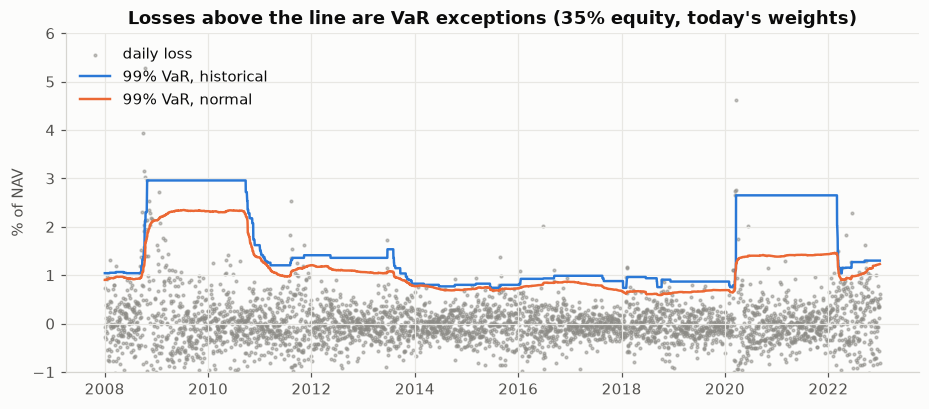

exceptions 2008-2022: {'Historical': 46, 'Normal': 83}; expected at 99%: 38 over 3777 days


In [4]:
# The same models through time: rolling 500-day 99% VaR (today's weights) against the next day's loss
roll_hs = loss_all.rolling(WIN).quantile(0.99, interpolation="higher").shift(1)
roll_n = (loss_all.rolling(WIN).mean() + st.norm.ppf(0.99) * loss_all.rolling(WIN).std()).shift(1)
view = pd.DataFrame({"loss": loss_all, "Historical": roll_hs, "Normal": roll_n}).dropna().loc["2008":]
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(view.index, view["loss"] * 100, s=3, color=GREY, alpha=0.5, label="daily loss")
ax.plot(view.index, view["Historical"] * 100, color=BLUE, linewidth=1.6, label="99% VaR, historical")
ax.plot(view.index, view["Normal"] * 100, color=ORANGE, linewidth=1.6, label="99% VaR, normal")
ax.set(ylim=(-1, 6), ylabel="% of NAV", title="Losses above the line are VaR exceptions (35% equity, today's weights)")
ax.legend(loc="upper left")
plt.show()
exc = {k: int((view["loss"] > view[k]).sum()) for k in ["Historical", "Normal"]}
print(f"exceptions 2008-2022: {exc}; expected at 99%: {0.01 * len(view):.0f} over {len(view)} days")

**Finding:**
- **On a 1-in-100 day the 35% portfolio loses about USD 123,000–137,000 (1.2–1.4% of NAV)**, depending on the method.
- The methods disagree in a telling way. The normal model gives the **highest** 90% VaR but the **lowest** 99% VaR: it over-states ordinary bad days and under-states rare ones, because real returns have fat tails (the fitted Student-t has only 5.2 degrees of freedom). Historical, Student-t and Monte Carlo agree within about 5% at 99%.
- Through time (chart), both rolling models fail the same way: with today's weights, 2008–22 had **83 normal-VaR exceptions and 46 historical-VaR exceptions against 38 expected**. A 500-day window reacts too slowly to sudden regime changes (2008, 2020) and then stays too high for two years after (the flat plateaus).

**Decision:** report historical, parametric and Monte Carlo side by side as the brief requires, explain the crossover, and rely on a volatility-adjusted model (§5, notebook 04) for monitoring, because unconditional models cluster their exceptions.

## 2 · Why Expected Shortfall as well as VaR?

VaR says where the bad days start, not how bad they are. ES averages the losses beyond VaR. It is also **subadditive** (the risk of a combined portfolio is never more than the sum of the parts), which VaR is not. The textbook demonstration: two independent bonds, each losing 10 with probability 4%.

In [5]:
ratio = var_table.pivot(index="method", columns="confidence", values="ES / VaR")
ratio.loc["normal reference"] = [st.norm.pdf(st.norm.ppf(a)) / (1 - a) / st.norm.ppf(a) for a in ALPHAS]
display(ratio.round(3))

# subadditivity demo, exact distributions
p, L = 0.04, 10.0
single = {0.0: 1 - p, L: p}
pair = {0.0: (1 - p) ** 2, L: 2 * p * (1 - p), 2 * L: p**2}
def var_es(dist, a=0.95):
    xs = sorted(dist, reverse=True); tail, acc, var = 1 - a, 0.0, None
    es_sum = 0.0
    for x in xs:
        take = min(dist[x], tail - acc)
        if take > 0:
            es_sum += take * x; acc += take
        if var is None and sum(dist[y] for y in xs if y >= x) > tail:
            var = x
    return var, es_sum / tail
(v1, e1), (v2, e2) = var_es(single), var_es(pair)
pd.DataFrame({"one bond": [v1, e1], "two bonds (sum of parts)": [2 * v1, 2 * e1], "two-bond portfolio": [v2, e2]},
             index=["95% VaR", "95% ES"])

confidence,90%,95%,99%
method,,,
Historical,1.460,1.349,1.312
Monte Carlo (mv-t),1.526,1.405,1.305
Normal,1.357,1.248,1.143
Student-t,1.534,1.417,1.311
normal reference,1.369,1.254,1.146


,one bond,two bonds (sum of parts),two-bond portfolio
95% VaR,0.0,0.0,10.00
95% ES,8.0,16.0,10.32


**Finding:** at 99% the average loss beyond VaR is about **1.31× VaR** (historical), against 1.15× for a normal distribution: the tail is about 15% heavier than the normal model assumes. In the two-bond example, each bond has a 95% VaR of 0, yet together their VaR is 10: VaR says diversifying **adds** risk. ES behaves sensibly (10.3 together, at most the 16 of the parts).
**Decision:** report ES alongside VaR and use ES for limits and risk budgeting (brief Layer 3): it measures how bad the bad days are and it rewards diversification.

## 3 · The extreme tail: Extreme Value Theory

Peaks-over-threshold: losses above a high threshold u are fitted with a Generalised Pareto Distribution (shape ξ, scale β). The threshold must be justified, not picked: too low and the GPD is wrong, too high and there are too few points. We use the whole 2004–2022 history of today's weights (4,560 days) because extremes are rare.

**Hypotheses for the fit:** the GPD fits the exceedances (goodness-of-fit test); ξ is stable above the chosen threshold.

In [6]:
Lf = loss_all.to_numpy()
def gpd_fit(y):
    xi, _, beta = st.genpareto.fit(y, floc=0)
    return xi, beta
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)      # the profile search touches the GPD support boundary

def profile_ci(y, xi_hat, level=0.95):
    nll = lambda xi, lb: -st.genpareto.logpdf(y, xi, 0, np.exp(lb)).sum()
    best = min(nll(xi_hat, lb) for lb in np.linspace(np.log(y.mean()) - 2, np.log(y.mean()) + 2, 200))
    crit = st.chi2.ppf(level, 1) / 2
    grid = np.linspace(xi_hat - 0.6, xi_hat + 0.6, 121)
    prof = [optimize.minimize_scalar(lambda lb: nll(g, lb), bounds=(np.log(y.mean()) - 4, np.log(y.mean()) + 4),
                                     method="bounded").fun for g in grid]
    inside = grid[np.array(prof) - best <= crit]
    return float(inside.min()), float(inside.max())

QS = [0.85, 0.875, 0.90, 0.925, 0.95, 0.975]
rows = []
for q in QS:
    u = np.quantile(Lf, q); y = Lf[Lf > u] - u
    xi, beta = gpd_fit(y)
    lo, hi = profile_ci(y, xi)
    cvm = st.cramervonmises(y, "genpareto", args=(xi, 0, beta)).pvalue
    n, nu = len(Lf), len(y)
    var99 = u + beta / xi * ((n / nu * 0.01) ** (-xi) - 1)
    es99 = var99 / (1 - xi) + (beta - xi * u) / (1 - xi) if xi < 1 else np.inf
    p10 = 1 - 1 / (252 * 10)
    rl10 = u + beta / xi * ((n / nu * (1 - p10)) ** (-xi) - 1)
    rows.append({"threshold quantile": q, "u %": u * 100, "exceedances": nu, "xi": xi, "xi 95% CI low": lo, "xi 95% CI high": hi,
                 "GOF p (Cramér-von Mises)": cvm, "99% VaR %": var99 * 100, "99% ES %": es99 * 100, "1-in-10-year loss %": rl10 * 100})
evt = pd.DataFrame(rows).set_index("threshold quantile")
# Rule: the lowest threshold whose xi lies inside the CI of every higher threshold (stability), with >= 100 exceedances
stable = [q for q in QS if all(evt.loc[h, "xi 95% CI low"] <= evt.loc[q, "xi"] <= evt.loc[h, "xi 95% CI high"] for h in QS if h > q)
          and evt.loc[q, "exceedances"] >= 100]
print(f"stability rule picks {stable[0] if stable else 'none'}: the lowest grid point, so the rule does not discriminate here")
Q_STAR = 0.90       # explicit choice: ~10% of the data (456 exceedances), the range the literature finds robust; see Finding
print(f"chosen threshold: {Q_STAR:.0%} quantile")
evt.round(3)

stability rule picks 0.85: the lowest grid point, so the rule does not discriminate here
chosen threshold: 90% quantile


,u %,exceedances,xi,xi 95% CI low,xi 95% CI high,GOF p (Cramér-von Mises),99% VaR %,99% ES %,1-in-10-year loss %
threshold quantile,,,,,,,,,
0.850,0.357,684,0.256,0.176,0.346,0.638,1.452,2.205,4.261
0.875,0.410,570,0.257,0.177,0.357,0.489,1.452,2.207,4.270
0.900,0.486,456,0.296,0.196,0.416,0.563,1.440,2.252,4.530
0.925,0.579,342,0.323,0.203,0.473,0.520,1.430,2.278,4.696
0.950,0.714,228,0.394,0.234,0.594,0.884,1.406,2.365,5.191
0.975,0.942,114,0.354,0.124,0.684,0.760,1.414,2.348,5.049


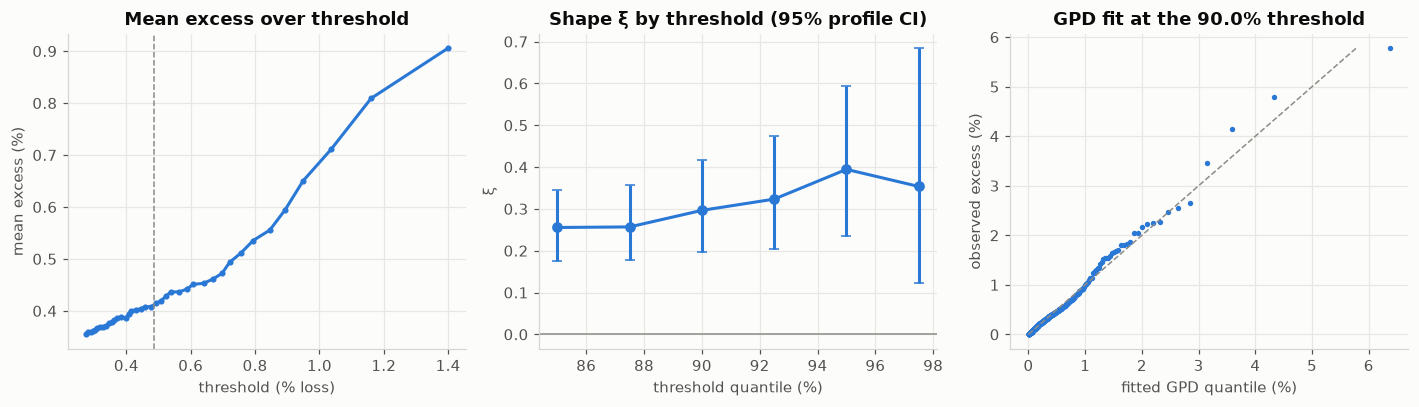

In [7]:
us = np.quantile(Lf, np.linspace(0.80, 0.99, 40))
me = [(Lf[Lf > u] - u).mean() for u in us]
u = np.quantile(Lf, Q_STAR); y = np.sort(Lf[Lf > u] - u); xi, beta = gpd_fit(y)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(us * 100, np.array(me) * 100, color=BLUE, marker="o", markersize=3)
axes[0].axvline(u * 100, color=GREY, linestyle="--", linewidth=1)
axes[0].set(title="Mean excess over threshold", xlabel="threshold (% loss)", ylabel="mean excess (%)")
axes[1].errorbar([q * 100 for q in QS], evt["xi"], yerr=[evt["xi"] - evt["xi 95% CI low"], evt["xi 95% CI high"] - evt["xi"]],
                 color=BLUE, marker="o", capsize=3)
axes[1].axhline(0, color=GREY, linewidth=1)
axes[1].set(title="Shape ξ by threshold (95% profile CI)", xlabel="threshold quantile (%)", ylabel="ξ")
pp = (np.arange(1, len(y) + 1) - 0.5) / len(y)
axes[2].plot(st.genpareto.ppf(pp, xi, 0, beta) * 100, y * 100, color=BLUE, marker="o", markersize=2.5, linestyle="none")
axes[2].plot([0, y.max() * 100], [0, y.max() * 100], color=GREY, linestyle="--", linewidth=1)
axes[2].set(title=f"GPD fit at the {Q_STAR:.1%} threshold", xlabel="fitted GPD quantile (%)", ylabel="observed excess (%)")
plt.tight_layout(); plt.show()

**Finding:**
- **The tail is heavy but well-behaved.** ξ is about 0.26–0.39, so the tail is heavy (ξ > 0) while variance and ES stay finite (ξ < 0.5, well below 1). The GPD is not rejected at any threshold (Cramér-von Mises p = 0.49–0.88; these p-values are generous because the parameters were estimated from the same data).
- **The automatic stability rule picked the lowest grid point.** ξ's confidence intervals widen at high thresholds, so every lower ξ looks "stable". The fit chart shows why that is risky: at 85% the four largest losses sit above the line, so the extremes are under-fitted. We fix the threshold at **90%** instead (456 exceedances, about 10% of the data, the range the literature finds robust) and say so.
- **The 99% figures barely depend on the threshold:** 99% VaR 1.41–1.45%, 99% ES 2.21–2.37%. **The once-in-a-decade loss does: 4.3–5.2% of NAV (about USD 430,000–520,000).**

**Decision:** quote the 99% EVT numbers as point estimates and the once-in-a-decade loss **as a range**. Uncertainty about the far tail is itself the finding the committee needs (brief: "how confident are you in your risk estimates?").

## 4 · Setting the risk limits: through-the-cycle ES, calibrated from the crisis budget

The IPS limit must not depend on the volatility of one particular week (gap G4). We measure, for every point on the frontier, its 99% ES on the **development data (2004–2018, which includes the GFC)** and its loss if today's weights had been held through the GFC. The point whose GFC loss equals the crisis budget D_max sets the volatility and ES limits.

In [8]:
dev = R.loc[:"2018-12-31"]
gfc = R.loc[(R.index > "2007-10-09") & (R.index <= "2009-03-09")]
y2022 = R.loc[(R.index > "2022-01-03") & (R.index <= "2022-10-12")]
def path_dd(r):
    v = (1 + r).cumprod(); return float((v / np.maximum(v.cummax(), 1.0) - 1).min())
rows = []
for x, wx in WEIGHTS.items():
    l = -(dev @ wx); es = at_es(l, 0.99)
    rows.append({"equity": f"{x:.0%}", "dev 99% ES %": es * 100, "dev vol %": l.std() * np.sqrt(252) * 100,
                 "ES99 / daily σ": es / l.std(),
                 "GFC loss % (today's weights)": -path_dd(gfc @ wx) * 100, "2022 loss %": -path_dd(y2022 @ wx) * 100})
cal = pd.DataFrame(rows).set_index("equity")
gfc_l = cal["GFC loss % (today's weights)"].to_numpy(); xs = np.array(LEVELS)
calib = {}
for dmax in [0.20, 0.25]:
    x_at = float(np.interp(dmax * 100, gfc_l, xs))
    calib[f"D_max {dmax:.0%}"] = {"equity share at the budget": x_at,
                                  "volatility limit %": float(np.interp(x_at, xs, cal["dev vol %"])),
                                  "99% ES limit %": float(np.interp(x_at, xs, cal["dev 99% ES %"]))}
display(cal.round(2))
pd.DataFrame(calib).T.style.format({"equity share at the budget": "{:.0%}", "volatility limit %": "{:.2f}", "99% ES limit %": "{:.2f}"})

,dev 99% ES %,dev vol %,ES99 / daily σ,GFC loss % (today's weights),2022 loss %
equity,,,,,
20%,1.47,6.27,3.72,18.17,16.17
25%,1.65,6.67,3.92,20.24,17.04
30%,1.88,7.31,4.09,22.36,17.90
35%,2.16,8.15,4.21,24.41,18.83
40%,2.43,9.10,4.24,26.59,19.55
45%,2.71,10.11,4.26,29.00,20.21
50%,2.99,11.14,4.26,31.88,20.87


,equity share at the budget,volatility limit %,99% ES limit %
D_max 20%,24%,6.62,1.63
D_max 25%,36%,8.40,2.23


**Finding:**
- **The crisis budget D_max is the lever that sets everything else.** With today's weights, a GFC-style crisis would cost 18% at 20% equity and 32% at 50% equity. A 25% budget allows about **36% equity**, with a volatility limit of 8.4% and a 99% ES limit of 2.23%. A 20% budget allows only about 24% equity (limits 6.6% and 1.63%).
- ES99 is 3.7–4.3 times daily volatility across the frontier, consistent with the independent review (3.8–4.15), so the two limits are now consistent by construction.
- **A warning for a conservative investor:** in the 2022 rate shock, even the 20% portfolio would have lost 16%, almost as much as in the GFC (18%). Low equity does not protect against a rate shock, because the bonds are what fall (notebook 01 §8).

**Decision:** decision D2 (D_max) is the most important number the team sets. With D_max = 25% (provisional), the limits are volatility ≤ 8.4% and 99% 1-day ES ≤ 2.23% through the cycle, and the frontier is capped near 36% equity. Replace the old IPS limits (8% / 1.5%), which contradicted each other.

## 5 · Is the volatility model right? GARCH residual analysis (hypothesis H3)

The champion risk model (conditional EVT) first divides returns by a GARCH volatility forecast, then models the leftover "standardised residuals" z. That only works if z is **random**: no autocorrelation (Ljung-Box on z), no remaining volatility clustering (Ljung-Box on z², ARCH-LM), and a distribution that matches the assumption (QQ plot).

**H3 (stated before testing):** the GARCH(1,1) standardised residuals of today's 35%-equity portfolio, 2004–2022, show no autocorrelation and no remaining clustering. We also fit GJR-GARCH, which lets bad news raise volatility more than good news, in case the plain model fails.

,AIC,persistence,t dof,"LB p, z (10)","LB p, z (20)","LB p, z² (10)","ARCH-LM p, z (10)","raw returns: LB p, r² (10)"
model,,,,,,,,
"GARCH(1,1), t",4162.3234,0.9897,7.7599,0.1863,0.0722,0.0067,0.0062,0.0
"GJR-GARCH(1,1), t",4087.1883,0.9871,8.3867,0.1750,0.0640,0.1561,0.1477,0.0


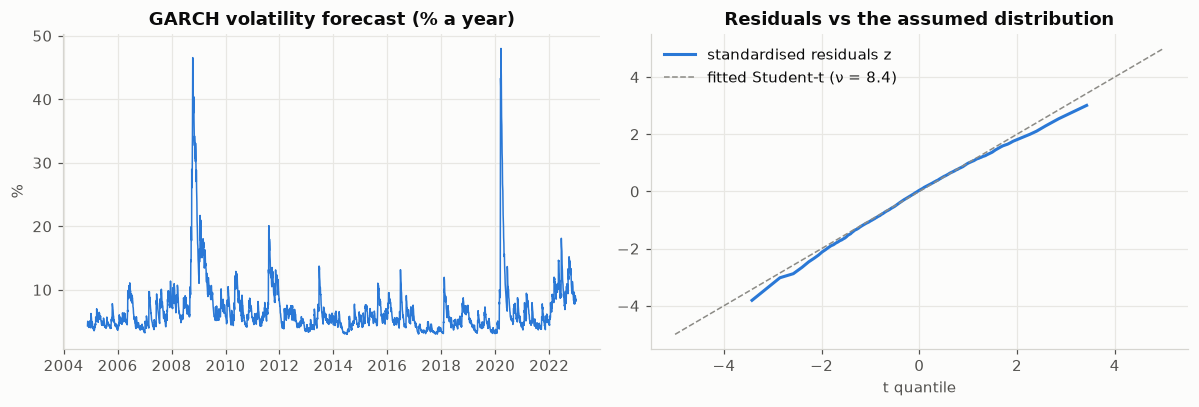

In [9]:
y_ret = -loss_all * 100                                   # percent returns for numerical stability
rows, fits = [], {}
for name, o in [("GARCH(1,1), t", 0), ("GJR-GARCH(1,1), t", 1)]:
    res = arch_model(y_ret, mean="Constant", vol="GARCH", p=1, o=o, q=1, dist="t").fit(disp="off")
    z = res.std_resid.dropna(); fits[name] = (res, z)
    pers = res.params["alpha[1]"] + res.params["beta[1]"] + 0.5 * res.params.get("gamma[1]", 0.0)
    rows.append({"model": name, "AIC": res.aic, "persistence": pers, "t dof": res.params["nu"],
                 "LB p, z (10)": acorr_ljungbox(z, lags=[10])["lb_pvalue"].iloc[0],
                 "LB p, z (20)": acorr_ljungbox(z, lags=[20])["lb_pvalue"].iloc[0],
                 "LB p, z² (10)": acorr_ljungbox(z**2, lags=[10])["lb_pvalue"].iloc[0],
                 "ARCH-LM p, z (10)": het_arch(z, nlags=10)[1],
                 "raw returns: LB p, r² (10)": acorr_ljungbox(y_ret**2, lags=[10])["lb_pvalue"].iloc[0]})
garch_tab = pd.DataFrame(rows).set_index("model")
display(garch_tab.round(4))
res, z = fits["GJR-GARCH(1,1), t"] if garch_tab.loc["GJR-GARCH(1,1), t", "AIC"] < garch_tab.loc["GARCH(1,1), t", "AIC"] else fits["GARCH(1,1), t"]
nu = res.params["nu"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(res.conditional_volatility.index, res.conditional_volatility * np.sqrt(252), color=BLUE, linewidth=1)
axes[0].set(title="GARCH volatility forecast (% a year)", ylabel="%")
qq = np.linspace(0.002, 0.998, 300)
ref = st.t.ppf(qq, nu) * np.sqrt((nu - 2) / nu)
axes[1].plot(ref, np.quantile(z, qq), color=BLUE, label="standardised residuals z")
axes[1].plot([-5, 5], [-5, 5], color=GREY, linestyle="--", linewidth=1, label=f"fitted Student-t (ν = {nu:.1f})")
axes[1].set(title="Residuals vs the assumed distribution", xlabel="t quantile")
axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

**Finding:** **H3 is rejected for plain GARCH(1,1) and supported for GJR-GARCH.**
- Plain GARCH removes the autocorrelation (Ljung-Box on z: p = 0.19) but leaves volatility clustering in the residuals (Ljung-Box on z²: p = 0.007; ARCH-LM: p = 0.006).
- GJR-GARCH, which lets losses raise volatility more than gains, leaves none (p = 0.16 and 0.15) and fits much better (AIC 4,087 against 4,162).
- Both are very persistent (0.99): a volatility shock takes months to fade.
- The pipeline's champion (conditional EVT) and GARCH-FHS both use the **plain** model (`risk/garch.py`), which is consistent with the champion under-forecasting 99% VaR by about 15% (gap G9).

**Decision:** add a GJR-GARCH filter as a candidate and compare it with the current champion on validation in notebook 04, **before** the freeze. Whatever wins, the choice must be made on validation only. If GJR is not adopted, disclose the remaining clustering as a model limitation.

## 6 · Who carries the risk? Euler ES contributions (risk budgeting)

Each asset's contribution to ES is its weight times its average loss on the portfolio's worst 1% of days (Euler allocation; contributions add up exactly to total ES). Comparing each asset's **share of capital** with its **share of ES** shows where the risk really sits (gap G23). Proposed rule (decision D8, provisional): no single ETF above 40% of ES.

sum of contributions 2.3034% = total 99% ES 2.3034%  (Euler check)


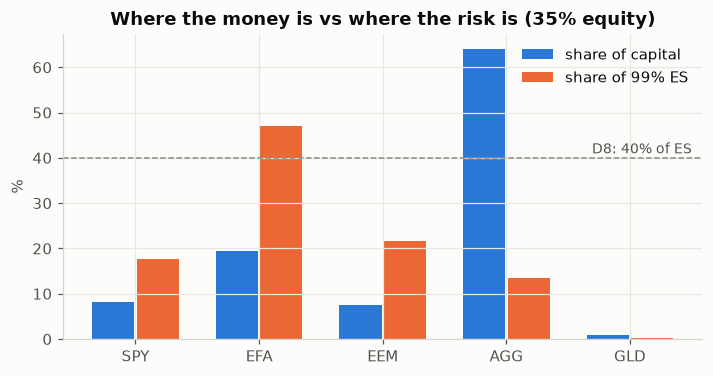

,capital share,ES contribution %,ES share
SPY,8.2%,0.405,17.6%
EFA,19.4%,1.083,47.0%
EEM,7.4%,0.501,21.7%
AGG,64.1%,0.311,13.5%
GLD,0.9%,0.003,0.1%


In [10]:
q = loss_all.quantile(0.99)
tail = loss_all >= q
contrib = pd.Series(w * (-R.loc[tail].mean().to_numpy()), index=TICKERS)
es_total = float(loss_all[tail].mean())
budget = pd.DataFrame({"capital share": w, "ES contribution %": contrib * 100, "ES share": contrib / es_total}, index=TICKERS)
budget = budget[budget["capital share"] > 1e-4]
print(f"sum of contributions {contrib.sum() * 100:.4f}% = total 99% ES {es_total * 100:.4f}%  (Euler check)")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
xp = np.arange(len(budget))
ax.bar(xp - 0.18, budget["capital share"] * 100, width=0.34, color=BLUE, label="share of capital")
ax.bar(xp + 0.18, budget["ES share"] * 100, width=0.34, color=ORANGE, label="share of 99% ES")
ax.axhline(40, color=GREY, linestyle="--", linewidth=1)
ax.text(len(budget) - 0.5, 41, "D8: 40% of ES", color=INK2, fontsize=9, ha="right")
ax.set_xticks(xp, budget.index)
ax.set(ylabel="%", title="Where the money is vs where the risk is (35% equity)")
ax.legend(loc="upper right")
plt.show()
budget.style.format({"capital share": "{:.1%}", "ES contribution %": "{:.3f}", "ES share": "{:.1%}"})

**Finding:** **EFA holds 19% of the money but carries 47% of the tail risk**, above the provisional 40% cap (decision D8). EEM holds 7% and carries 22%; SPY holds 8% and carries 18%. AGG holds 64% of the money and carries only 14% of the tail risk. The contributions add up exactly to total ES (Euler check).
**Decision:** this is the sizing action the brief asks for (§8.6). The minimum-variance optimiser over-weights international equity, which concentrates tail risk there. Together with notebook 02 (international equity also cost return), there are now **two independent reasons** to move the equity sleeve towards SPY: cap EFA so its ES share is at most 40% and re-measure in notebook 06. Sizing sentence for the memo: “EFA is 19% of the portfolio but 47% of its worst-day risk; we cap it.”

## 7 · Reconciliation with the pipeline

The pipeline's risk snapshot uses its own focus portfolio (Min CVaR) on the 500 days to 2022-12-30. With those weights, our historical and normal VaR/ES must match.

In [11]:
status = json.loads((ART / "status.json").read_text())
wp = np.array([status["weights"][t] for t in TICKERS])
lp = -(R.iloc[-WIN:] @ wp)
snap = pd.read_parquet(ART / "risk_snapshot.parquet").set_index(["model", "alpha"])
rows = []
for a in [0.95, 0.99]:
    for name, f in [("Historical", hs), ("Normal", normal)]:
        v, e = f(lp, a)
        rows.append({"model": name, "alpha": a, "VaR ours": v, "VaR pipeline": snap.loc[(name, a), "var"],
                     "ES ours": e, "ES pipeline": snap.loc[(name, a), "es"]})
rec = pd.DataFrame(rows)
rec["max abs diff"] = np.maximum((rec["VaR ours"] - rec["VaR pipeline"]).abs(), (rec["ES ours"] - rec["ES pipeline"]).abs())
rec.round(6)

,model,alpha,VaR ours,VaR pipeline,ES ours,ES pipeline,max abs diff
0,Historical,0.95,0.0074,0.0074,0.0099,0.0099,0.0
1,Normal,0.95,0.0076,0.0076,0.0095,0.0095,0.0
2,Historical,0.99,0.0124,0.0124,0.0143,0.0143,0.0
3,Normal,0.99,0.0107,0.0107,0.0122,0.0122,0.0


## 8 · Does diversification actually help? (booklet p. 4: "diversification benefits", gap G27)

Notebook 02 showed the seven-ETF mix earned **no extra return** over a plain SPY/AGG mix. The benefit the committee should expect is in **risk**: losses on different assets do not all happen together, so the portfolio's tail loss is smaller than the weighted sum of each asset's tail loss. We measure that saving in dollars, the diversification ratio, and **how much of the benefit survives a crisis**, which is when it matters.

- **ES saving** = Σ wᵢ·ESᵢ (each asset's own 99% ES, weighted) − ES of the portfolio. ES is subadditive (§2), so the saving is never negative.
- **Diversification ratio** = Σ wᵢσᵢ / σ_portfolio (1 = no diversification).

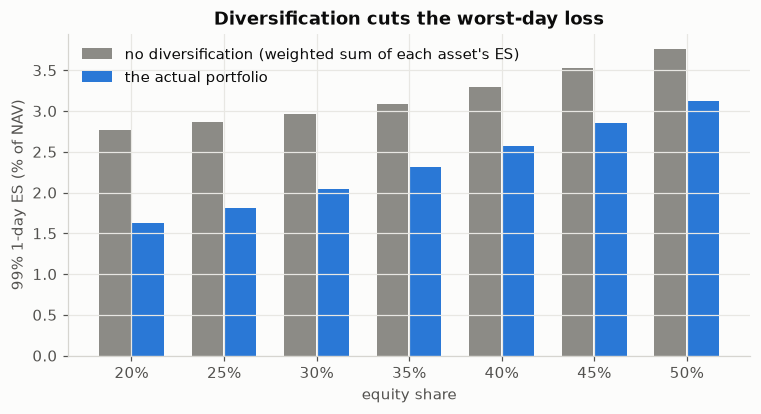

,sum of standalone 99% ES %,portfolio 99% ES %,ES saving $ (99%),saving share,diversification ratio,"saving share, calm days (95% ES)","saving share, crisis days (95% ES)"
equity,,,,,,,
20%,2.76,1.62,"$113,919",41%,1.61,42%,38%
25%,2.86,1.81,"$104,885",37%,1.55,41%,33%
30%,2.96,2.05,"$91,259",31%,1.46,37%,28%
35%,3.08,2.31,"$76,996",25%,1.37,32%,23%
40%,3.29,2.58,"$71,451",22%,1.32,28%,20%
45%,3.53,2.85,"$67,824",19%,1.28,25%,18%
50%,3.76,3.12,"$63,934",17%,1.24,22%,16%


In [12]:
CRISIS_DAYS = ((R.index > "2007-10-09") & (R.index <= "2009-03-09")) | ((R.index > "2020-02-19") & (R.index <= "2020-03-23")) | \
              ((R.index > "2022-01-03") & (R.index <= "2022-10-12"))
def div_benefit(wx, days, a):
    Rd = R.loc[days]
    standalone = sum(wx[i] * at_es(-Rd.iloc[:, i].to_numpy(), a) for i in range(7) if wx[i] > 1e-6)
    port = at_es(-(Rd @ wx).to_numpy(), a)
    return standalone, port
rows = []
for x, wx in WEIGHTS.items():
    sa, pe = div_benefit(wx, np.ones(len(R), bool), 0.99)
    sa_c, pe_c = div_benefit(wx, CRISIS_DAYS, 0.95)
    sa_n, pe_n = div_benefit(wx, ~CRISIS_DAYS, 0.95)
    vol = R.std().to_numpy() * np.sqrt(252)
    rows.append({"equity": f"{x:.0%}", "sum of standalone 99% ES %": sa * 100, "portfolio 99% ES %": pe * 100,
                 "ES saving $ (99%)": (sa - pe) * NAV, "saving share": 1 - pe / sa,
                 "diversification ratio": float(wx @ vol) / float((R @ wx).std() * np.sqrt(252)),
                 "saving share, calm days (95% ES)": 1 - pe_n / sa_n, "saving share, crisis days (95% ES)": 1 - pe_c / sa_c})
dv = pd.DataFrame(rows).set_index("equity")
fig, ax = plt.subplots(figsize=(8, 3.8))
xp = np.arange(len(dv))
ax.bar(xp - 0.18, dv["sum of standalone 99% ES %"], width=0.34, color=GREY, label="no diversification (weighted sum of each asset's ES)")
ax.bar(xp + 0.18, dv["portfolio 99% ES %"], width=0.34, color=BLUE, label="the actual portfolio")
ax.set_xticks(xp, dv.index)
ax.set(ylabel="99% 1-day ES (% of NAV)", xlabel="equity share", title="Diversification cuts the worst-day loss")
ax.legend(loc="upper left")
plt.show()
dv.style.format({"sum of standalone 99% ES %": "{:.2f}", "portfolio 99% ES %": "{:.2f}", "ES saving $ (99%)": "${:,.0f}",
                 "saving share": "{:.0%}", "diversification ratio": "{:.2f}", "saving share, calm days (95% ES)": "{:.0%}",
                 "saving share, crisis days (95% ES)": "{:.0%}"})

In [13]:
# Crisis drawdowns: the portfolio vs the weighted sum of its assets' own worst losses in each crisis
rows = []
for name, (a, b) in {"GFC 2008": ("2007-10-09", "2009-03-09"), "COVID 2020": ("2020-02-19", "2020-03-23"),
                     "Rate shock 2022": ("2022-01-03", "2022-10-12")}.items():
    seg = R.loc[(R.index > a) & (R.index <= b)]
    each = sum(w[i] * path_dd(seg.iloc[:, i]) for i in range(7) if w[i] > 1e-6)
    rows.append({"crisis": name, "weighted sum of asset losses %": -each * 100, "portfolio loss %": -path_dd(seg @ w) * 100,
                 "loss avoided by diversification %": (path_dd(seg @ w) - each) * 100})
pd.DataFrame(rows).set_index("crisis").round(2)

,weighted sum of asset losses %,portfolio loss %,loss avoided by diversification %
crisis,,,
GFC 2008,29.78,24.41,5.36
COVID 2020,17.62,15.52,2.10
Rate shock 2022,19.40,18.83,0.56


**Finding:** diversification gives the endowment a real, measurable benefit, but **not in every crisis**.
- **In risk terms it clearly pays.** For the 35% portfolio, the worst-day loss (99% ES) is 2.31% of NAV instead of 3.08% if every holding's tail loss counted in full: a saving of **about USD 77,000 on a bad day**, a quarter of the tail risk (diversification ratio 1.37).
- **The benefit shrinks when it is needed most.** Of the tail risk it removes, 32% on calm days falls to 23% on crisis days.
- **It depends on the type of crisis.** Diversification avoided 5.4 percentage points of loss in the GFC (24.4% instead of 29.8%) and 2.1 points in COVID, but **only 0.6 points in the 2022 rate shock**, when stocks and bonds fell together. That is the rate-hiking regime found in notebook 01 §8, seen from the portfolio's side.

**Decision:** the memo shows diversification as **insurance with a known weak spot**: it saved about USD 540,000 in a GFC-type crisis on USD 10M, but almost nothing in a 2022-type rate shock. That weak spot is why the hypothetical stagflation scenario (notebook 05) uses the rate-hiking correlation, and why gold and a crisis budget (D2) matter.

**Finding:** with the pipeline's weights, our historical and normal VaR and ES at 95% and 99% match its risk snapshot exactly (differences of 0).

## Evidence table and what it means for the endowment

| Claim | Evidence | Status |
|---|---|---|
| Returns have fat tails: normal VaR under-states rare losses | §1 crossover; ES/VaR 1.31 vs 1.15; 83 vs 38 exceptions | **Strong** |
| ES is subadditive, VaR is not | §2 exact example | **Strong** (mathematical) |
| The GPD fits the tail; ξ ≈ 0.3 (finite ES) | §3: GOF p ≥ 0.49 at all thresholds; CI excludes 0 and 1 | **Strong** for 99%; the once-in-a-decade loss is uncertain (4.3–5.2%) |
| H3: GARCH residuals are random | §5: plain GARCH fails on z²; GJR passes | **Rejected for the current champion's filter; supported for GJR** |
| Risk is concentrated in international equity | §6: EFA 47% of ES with 19% of capital | **Strong** (for this window; recheck at the decision date) |
| The limits are consistent once calibrated from D_max | §4 | **Strong** |
| Diversification reduces tail risk (booklet p. 4) | §8: USD 77k saved on a bad day (25% of tail risk); 5.4 pp of GFC loss avoided, only 0.6 pp in 2022 | **Strong**, with a known weak spot (rate shocks) |

**What this means for the endowment (input to the memo), at 35% equity on USD 10M:**
1. **A bad day** (1 in 100): lose about **USD 125,000–135,000**; on such days the average loss is about **USD 175,000**.
2. **A once-in-a-decade day:** about **USD 430,000–520,000**. We give a range on purpose: rare events are where models are least certain.
3. **A GFC-type crisis** with today's weights: about **24%** (USD 2.4M); a 2022-type rate shock: about **19%**, even though the portfolio is two-thirds bonds.
4. **The team's choice of crisis budget (D2) sets the equity level**: 25% allows about 36% equity; 20% allows about 24%.
5. **Two model actions before the freeze:** test GJR-GARCH against the champion (notebook 04), and cap EFA's tail-risk share (notebook 06).